<a href="https://colab.research.google.com/github/anushka-dev18/3Skill/blob/main/Wine_Quality_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Upload Excel file
print("Upload your wine_quality_dataset Excel file:")
uploaded = files.upload()

# Get uploaded file name dynamically
file_name = list(uploaded.keys())[0]

# Load dataset
if file_name.endswith('.xlsx') or file_name.endswith('.xls'):
    df = pd.read_excel(file_name)
else:
    df = pd.read_csv(file_name)

print("\nDataset successfully loaded!")

Upload your wine_quality_dataset Excel file:


Saving winequality (1) (1).csv to winequality (1) (1).csv

Dataset successfully loaded!


--- First 5 Rows ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

--- Summary Statistics ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000



--- Missing Values Count ---
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


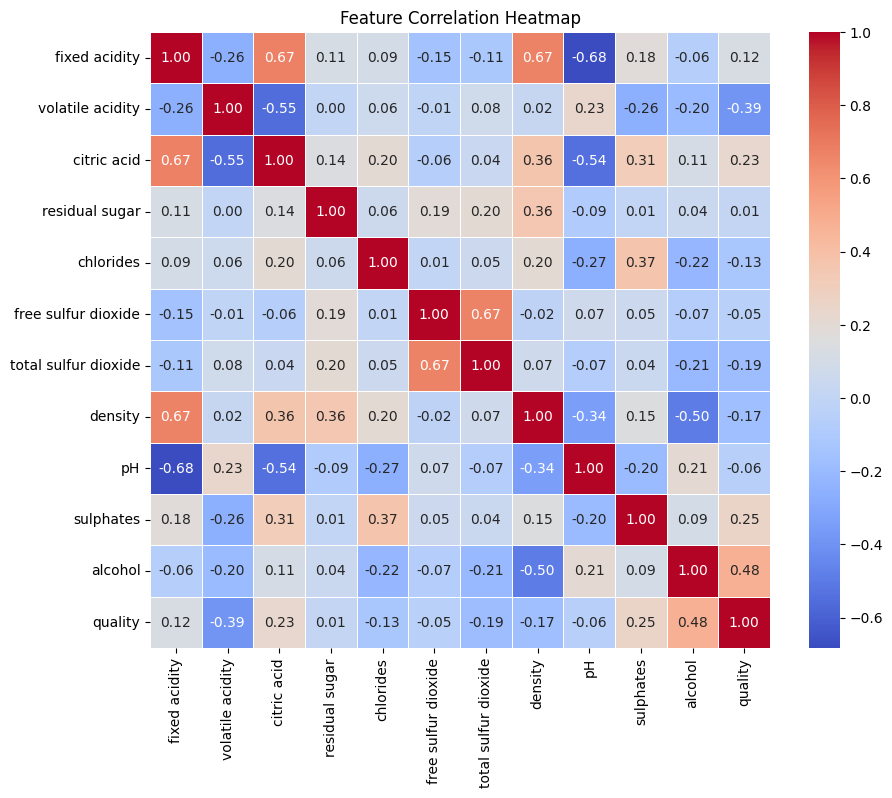


--- Correlation of Features with 'quality' ---
quality                 1.000000
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64


In [ ]:
# First 5 rows
print("--- First 5 Rows ---")
display(df.head())

# Dataset info
print("\n--- Dataset Info ---")
df.info()

# Summary statistics
print("\n--- Summary Statistics ---")
display(df.describe())

# Check missing values
print("\n--- Missing Values Count ---")
print(df.isnull().sum())

# Correlation Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

# Print specific correlation with quality
print("\n--- Correlation of Features with 'quality' ---")
print(df.corr()['quality'].sort_values(ascending=False))

In [ ]:
from sklearn.model_selection import train_test_split

# Create binary target
df['quality_label'] = df['quality'].apply(lambda x: 1 if x >= 7 else 0)

# Check class distribution
print("Target Class Distribution:")
print(df['quality_label'].value_counts())

# Separate features (X) and target (y)
X = df.drop(columns=['quality', 'quality_label'])
y = df['quality_label']

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTrain set size: {X_train.shape[0]} samples")
print(f"Test set size:  {X_test.shape[0]} samples")

Target Class Distribution:
quality_label
0    1382
1     217
Name: count, dtype: int64

Train set size: 1279 samples
Test set size:  320 samples


=== Logistic Regression (Unscaled) ===
Accuracy:  0.8938
Precision: 0.7368
Recall:    0.3256
F1-Score:  0.4516



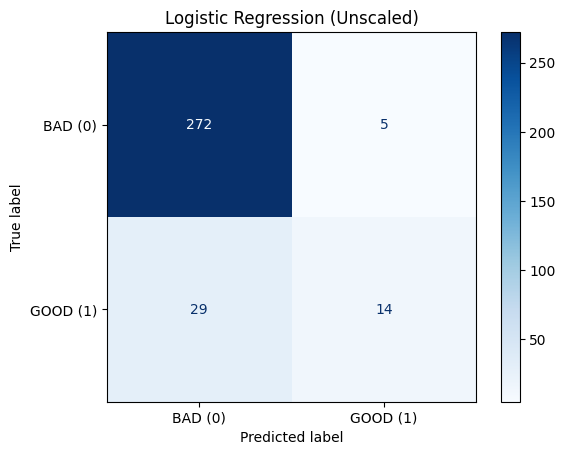

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Helper function to evaluate and visualize models
def evaluate_model(model, X_t, y_t, title="Model Evaluation"):
    y_pred = model.predict(X_t)

    acc = accuracy_score(y_t, y_pred)
    prec = precision_score(y_t, y_pred, zero_division=0)
    rec = recall_score(y_t, y_pred, zero_division=0)
    f1 = f1_score(y_t, y_pred, zero_division=0)

    print(f"=== {title} ===")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}\n")

    # Plot Confusion Matrix
    cm = confusion_matrix(y_t, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['BAD (0)', 'GOOD (1)'])
    disp.plot(cmap='Blues')
    plt.title(title)
    plt.grid(False)
    plt.show()

    return {'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1}

# Train unscaled model
lr_unscaled = LogisticRegression(max_iter=1000, random_state=42)
lr_unscaled.fit(X_train, y_train)

# Evaluate
unscaled_results = evaluate_model(lr_unscaled, X_test, y_test, "Logistic Regression (Unscaled)")

=== Logistic Regression (Scaled) ===
Accuracy:  0.8938
Precision: 0.6957
Recall:    0.3721
F1-Score:  0.4848



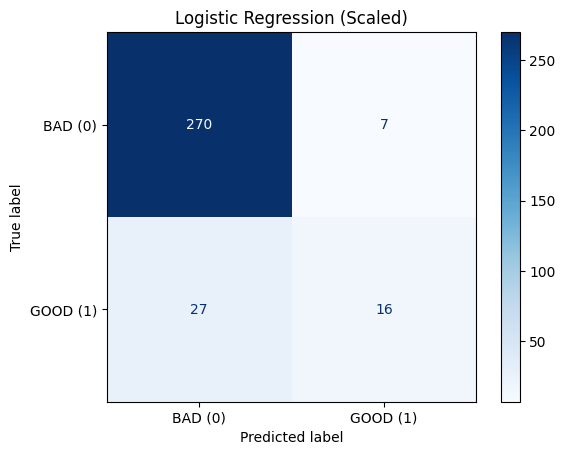

--- Scaling Impact Comparison ---


,Accuracy,Precision,Recall,F1-Score
Unscaled LR,0.89375,0.736842,0.325581,0.451613
Scaled LR,0.89375,0.695652,0.372093,0.484848


In [ ]:
from sklearn.preprocessing import StandardScaler

# Fit scaler on training data, transform both train and test
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train scaled model
lr_scaled = LogisticRegression(max_iter=1000, random_state=42)
lr_scaled.fit(X_train_scaled, y_train)

# Evaluate scaled model
scaled_results = evaluate_model(lr_scaled, X_test_scaled, y_test, "Logistic Regression (Scaled)")

# Comparison Table
scaling_comp = pd.DataFrame([unscaled_results, scaled_results], index=['Unscaled LR', 'Scaled LR'])
print("--- Scaling Impact Comparison ---")
display(scaling_comp)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Model dictionary
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42)
}

results = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0)
    }

comparison_df = pd.DataFrame(results).T
print("--- Model Comparison Summary ---")
display(comparison_df)

--- Model Comparison Summary ---


,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.89375,0.695652,0.372093,0.484848
K-Nearest Neighbors,0.89375,0.666667,0.418605,0.514286
Decision Tree,0.90625,0.638298,0.697674,0.666667


Best Hyperparameters: {'criterion': 'entropy', 'max_depth': None, 'min_samples_split': 2}
=== Tuned Decision Tree Model ===
Accuracy:  0.9250
Precision: 0.7317
Recall:    0.6977
F1-Score:  0.7143



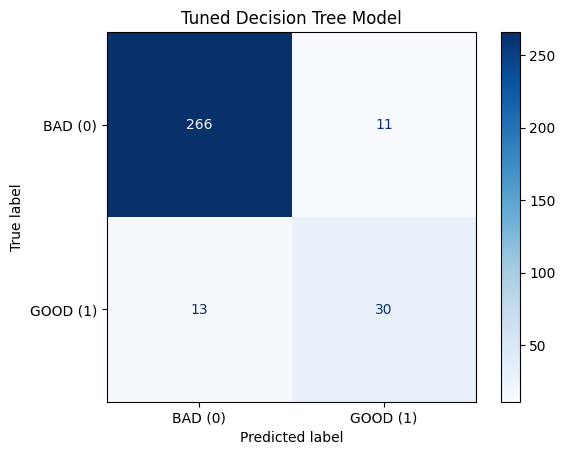

In [ ]:
from sklearn.model_selection import GridSearchCV

# Parameter grid for Decision Tree
param_grid = {
    'max_depth': [3, 5, 8, 12, None],
    'min_samples_split': [2, 5, 10],
    'criterion': ['gini', 'entropy']
}

dt = DecisionTreeClassifier(random_state=42)
grid_search = GridSearchCV(estimator=dt, param_grid=param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

print(f"Best Hyperparameters: {grid_search.best_params_}")

# Evaluate best tuned model
best_model = grid_search.best_estimator_
tuned_results = evaluate_model(best_model, X_test_scaled, y_test, "Tuned Decision Tree Model")

/tmp/ipykernel_1932/715844439.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_df, palette='viridis')


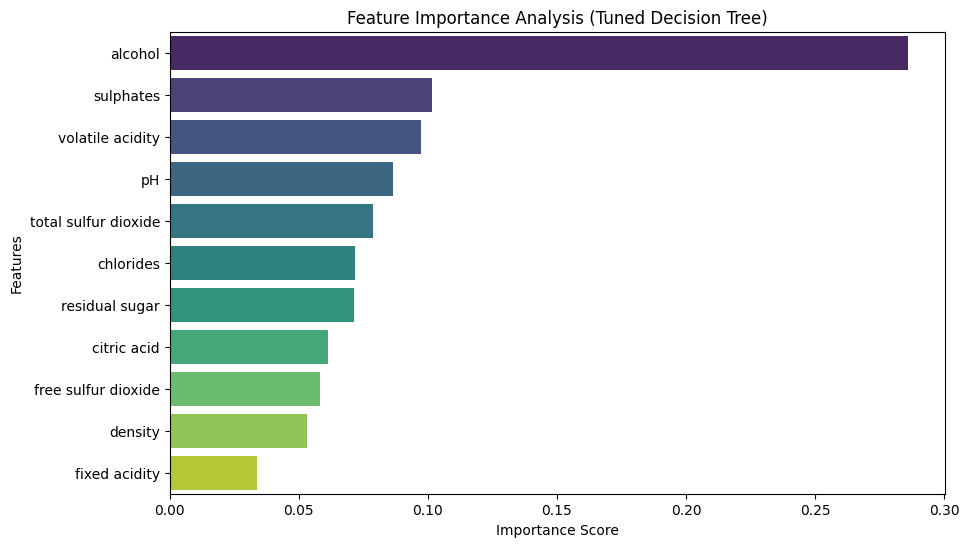

--- Top Ranking Features ---


,Feature,Importance
10,alcohol,0.285914
9,sulphates,0.101674
1,volatile acidity,0.097330
8,pH,0.086588
6,total sulfur dioxide,0.078875
4,chlorides,0.071724
3,residual sugar,0.071398
2,citric acid,0.061351
5,free sulfur dioxide,0.058129
7,density,0.053257


In [ ]:
# Get feature importances
importances = best_model.feature_importances_
feature_names = X.columns

# Dataframe for plotting
feat_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot feature importance
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_df, palette='viridis')
plt.title("Feature Importance Analysis (Tuned Decision Tree)")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

print("--- Top Ranking Features ---")
display(feat_df)